# Models

Input: `data/model_table.csv`, built by `python analysis/build_model_table.py` (column glossary at the top of that script). One row per game, home-team perspective.

| Section | Question |
|---|---|
| 1 | Do the de-vig methods disagree? |
| 2 | Are Kalshi / sportsbook prices calibrated against outcomes? |
| 3 | Does the sportsbook price carry information Kalshi missed (and vice versa)? |
| 4 | Do past Kalshi prices predict beyond the close? (not testable with current data) |
| 5 | Does the size of the disagreement shrink with liquidity? |
| 6 | Robustness: de-vig method, low-volume games, regular season only |
| 7 | Is anything exploitable after the spread and fees? |

Strong form is not testable with public price data!

**Conventions.**
- Standard errors are clustered by `game_date_et`, since same-day games share news and bettors.
- `gap = sportsbook − Kalshi`, matching the EDA.
- The primary de-vig method is **Cheung** (odds-ratio), fixed before looking at results.

A summary of answers to the research questions is at the end of the notebook.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

df = pd.read_csv("../data/model_table.csv", parse_dates=["start_time_utc"])
df = df.sort_values("start_time_utc").reset_index(drop=True)
df["post"] = df["postseason"].astype(int)
df["ba_spread_c"] = 100 * df["kalshi_ba_spread"]   # bid-ask spread in cents

SPORT_ORDER = ["nfl", "mlb", "nba", "nhl"]
SPORT_COLORS = {"nfl": "#2a78d6", "mlb": "#eb6834", "nba": "#1baf7a", "nhl": "#eda100"}
DEVIG_METHODS = ["proportional", "additive", "shin", "power", "cheung"]
PRIMARY_DEVIG = "cheung"
CONTROLS = "C(sport) + post + season_progress + months_since_start + n_sports_today + lopsided"

print(df.shape)
df.groupby("sport").size().reindex(SPORT_ORDER)

(4865, 49)


sport
nfl     276
mlb    1991
nba    1214
nhl    1384
dtype: int64

In [2]:
# ---------- helpers ----------
def cluster(data):
    # Arguments for .fit() that cluster standard errors by game date.
    return dict(cov_type="cluster", cov_kwds={"groups": pd.factorize(data["game_date_et"])[0]})


def logit(p, eps=1e-4):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))


def with_book_method(data, method):
    # Copy of data with every sportsbook-derived column recomputed for one de-vig method.
    d = data.copy()
    d["p_book"] = d[f"p_book_{method}"]
    d["logit_book"] = logit(d["p_book"])
    d["logit_gap"] = d["logit_book"] - d["logit_kalshi"]
    d["abs_logit_gap"] = d["logit_gap"].abs()
    d["gap_pp"] = 100 * (d["p_book"] - d["p_kalshi"])
    d["lopsided"] = (d["p_kalshi"] + d["p_book"] - 1).abs()
    return d


def calibration_fit(data, xcol):
    # logit P(home_win) = a + b * xcol, clustered SEs, joint Wald test of (a = 0, b = 1).
    res = smf.logit(f"home_win ~ {xcol}", data=data).fit(disp=0, **cluster(data))
    w = res.wald_test(f"Intercept = 0, {xcol} = 1", scalar=True)
    lo, hi = res.conf_int().loc[xcol]
    return res, {"n": int(res.nobs), "alpha": res.params["Intercept"], "alpha_se": res.bse["Intercept"],
                 "beta": res.params[xcol], "beta_lo": lo, "beta_hi": hi,
                 "wald_chi2": float(w.statistic), "wald_p": float(w.pvalue)}


def calibration_plot(data, p_col, label, bins=10, ax=None, **kw):
    # Reliability diagram: mean predicted vs observed win rate in probability deciles.
    ax = ax or plt.gca()
    b = pd.qcut(data[p_col], bins, duplicates="drop")
    g = data.groupby(b, observed=True).agg(pred=(p_col, "mean"), obs=("home_win", "mean"), n=("home_win", "size"))
    se = np.sqrt(g["obs"] * (1 - g["obs"]) / g["n"])
    ax.errorbar(g["pred"], g["obs"], yerr=1.96 * se, fmt="o", ms=4, capsize=2, label=label, **kw)
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("predicted P(home win)"); ax.set_ylabel("observed home win rate")
    return g


def by_sport(data, fn):
    # Run fn(sub_df) -> dict for the pooled sample and each sport; return a DataFrame.
    rows = [{"sample": "pooled", **fn(data)}]
    for s in SPORT_ORDER:
        rows.append({"sample": s, **fn(data[data["sport"] == s])})
    return pd.DataFrame(rows).set_index("sample")

## 1. De-vig sensitivity (descriptive)

The method is fixed up front as Cheung, and the others are reported for sensitivity. For a two-outcome market, Shin's method gives exactly the additive answer, so the `shin` and `additive` rows match.

In [3]:
rows = []
for m in DEVIG_METHODS:
    g = 100 * (df[f"p_book_{m}"] - df["p_kalshi"])
    rows.append({"method": m, "mean_gap_pp": g.mean(), "sd_gap_pp": g.std(),
                 "median_abs_gap_pp": g.abs().median(), "share_book_above_kalshi": (g > 0).mean()})
devig_table = pd.DataFrame(rows).set_index("method")
devig_table.round(3)

,mean_gap_pp,sd_gap_pp,median_abs_gap_pp,share_book_above_kalshi
method,,,,
proportional,-0.025,0.995,0.626,0.488
additive,0.138,0.912,0.596,0.565
shin,0.138,0.912,0.596,0.568
power,0.227,1.029,0.697,0.592
cheung,0.149,0.921,0.601,0.574


In [4]:
# Mean gap by sport under each method
pd.DataFrame({m: (100 * (df[f"p_book_{m}"] - df["p_kalshi"])).groupby(df["sport"]).mean()
              for m in DEVIG_METHODS}).reindex(SPORT_ORDER).round(3)

,proportional,additive,shin,power,cheung
sport,,,,,
nfl,-0.152,0.040,0.040,0.152,0.057
mlb,-0.017,0.126,0.126,0.200,0.133
nba,-0.066,0.143,0.143,0.267,0.163
nhl,0.025,0.171,0.171,0.246,0.178


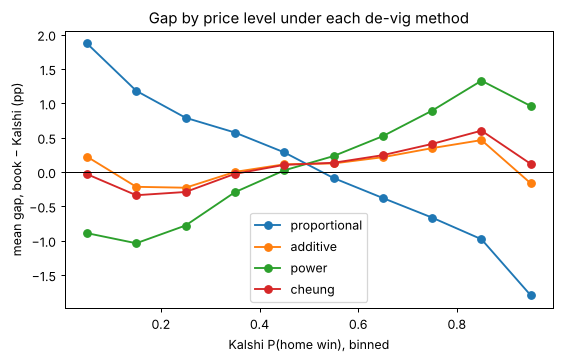

In [5]:
# Where do the methods disagree? Mean gap within bins of the Kalshi price.
bins = pd.cut(df["p_kalshi"], np.arange(0, 1.0001, 0.1))
fig, ax = plt.subplots(figsize=(7, 4))
for m in ["proportional", "additive", "power", "cheung"]:
    g = (100 * (df[f"p_book_{m}"] - df["p_kalshi"])).groupby(bins, observed=True).mean()
    ax.plot([iv.mid for iv in g.index], g.values, marker="o", label=m)
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("Kalshi P(home win), binned"); ax.set_ylabel("mean gap, book − Kalshi (pp)")
ax.set_title("Gap by price level under each de-vig method"); ax.legend();

**Reading section 1.**
- The de-vig choice changes the *sign* of the average gap: proportional gives −0.03 pp (book slightly below Kalshi), while Cheung, additive and power give +0.14 to +0.23 pp. This holds in every sport.
- The plot shows why. Proportional de-vigging gives favorites too much of the vig (book > Kalshi for longshots, book < Kalshi for favorites, by up to about 2 pp). Power tilts the other way. Cheung and additive sit flattest against Kalshi, i.e. closest to how Kalshi traders themselves price the favorite/longshot split.
- So any statement about the *direction* of the Kalshi–book gap is method-dependent and should be reported with this table. Statements about calibration against outcomes (section 2) are not, at least on the Kalshi side.

## 2. Calibration

For each source $s$: $\;\text{logit}\,P(\text{home\_win}=1) = \alpha + \beta\,\text{logit}(p_s)$.

- **Perfect calibration:** $\alpha = 0$ and $\beta = 1$, tested jointly with a Wald test.
- $\beta > 1$: prices are too compressed toward 50%, i.e. favorites underpriced (favorite-longshot bias).
- $\beta < 1$: prices are too extreme.
- $\alpha \ne 0$: a systematic home/away bias in prices.

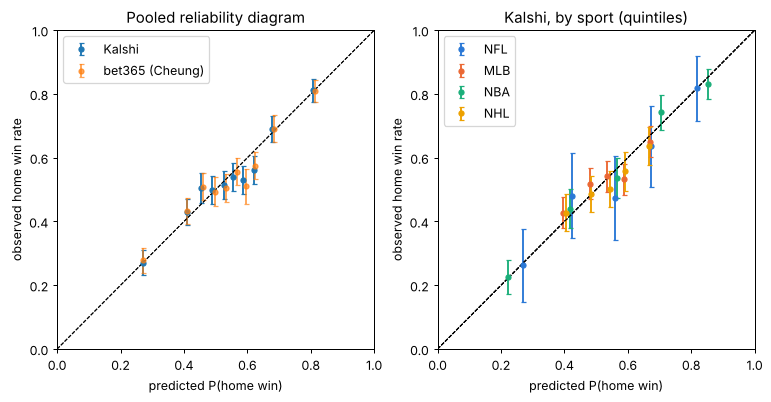

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))
calibration_plot(df, "p_kalshi", "Kalshi", ax=axes[0])
calibration_plot(df, "p_book", "bet365 (Cheung)", ax=axes[0], alpha=0.7)
axes[0].set_title("Pooled reliability diagram"); axes[0].legend()
for s in SPORT_ORDER:
    calibration_plot(df[df.sport == s], "p_kalshi", s.upper(), bins=5, ax=axes[1], color=SPORT_COLORS[s])
axes[1].set_title("Kalshi, by sport (quintiles)"); axes[1].legend();

### 2a–b. Calibration regressions, pooled and by sport

In [7]:
calib_kalshi = by_sport(df, lambda d: calibration_fit(d, "logit_kalshi")[1])
calib_book = by_sport(df, lambda d: calibration_fit(d, "logit_book")[1])
print("Kalshi")
display(calib_kalshi.round(3))
print("bet365 (Cheung)")
calib_book.round(3)

Kalshi
           n  alpha  alpha_se   beta  beta_lo  beta_hi  wald_chi2  wald_p
sample                                                                   
pooled  4865 -0.011     0.029  0.943    0.844    1.041      1.613   0.446
nfl      276 -0.065     0.140  0.967    0.682    1.253      0.258   0.879
mlb     1991  0.027     0.046  0.789    0.565    1.012      3.436   0.179
nba     1214  0.015     0.061  1.018    0.876    1.159      0.138   0.933
nhl     1384 -0.041     0.056  0.834    0.548    1.120      2.590   0.274
bet365 (Cheung)


,n,alpha,alpha_se,beta,beta_lo,beta_hi,wald_chi2,wald_p
sample,,,,,,,,
pooled,4865,-0.014,0.029,0.921,0.825,1.017,3.152,0.207
nfl,276,-0.059,0.140,0.915,0.647,1.183,0.555,0.758
mlb,1991,0.024,0.046,0.773,0.552,0.994,4.044,0.132
nba,1214,0.010,0.061,0.998,0.859,1.137,0.027,0.987
nhl,1384,-0.045,0.056,0.817,0.537,1.097,3.253,0.197


In [8]:
# Do the slopes differ by sport? Interaction model, Wald test that all sport:slope interactions are 0.
for x in ["logit_kalshi", "logit_book"]:
    res = smf.logit(f"home_win ~ C(sport) * {x}", data=df).fit(disp=0, **cluster(df))
    terms = [t for t in res.params.index if ":" in t]
    w = res.wald_test(", ".join(f"{t} = 0" for t in terms), scalar=True)
    print(f"{x}: equal slopes across sports  chi2({len(terms)}) = {w.statistic:.2f}, p = {w.pvalue:.3f}")

logit_kalshi: equal slopes across sports  chi2(3) = 3.50, p = 0.321
logit_book: equal slopes across sports  chi2(3) = 3.41, p = 0.332


### 2c. Does calibration change with season phase or platform maturity?

In [9]:
rows = []
for term in ["post", "season_progress", "months_since_start", "log_volume"]:
    res = smf.logit(f"home_win ~ logit_kalshi * {term}", data=df).fit(disp=0, **cluster(df))
    k = f"logit_kalshi:{term}"
    lo, hi = res.conf_int().loc[k]
    rows.append({"moderator": term, "slope_interaction": res.params[k], "lo": lo, "hi": hi, "p": res.pvalues[k]})
pd.DataFrame(rows).set_index("moderator").round(4)

,slope_interaction,lo,hi,p
moderator,,,,
post,-0.0894,-0.6154,0.4365,0.7390
season_progress,0.2195,-0.0913,0.5303,0.1663
months_since_start,0.0321,0.0004,0.0638,0.0473
log_volume,0.0067,-0.0323,0.0456,0.7374


### 2d. Which source forecasts better? Brier score and log loss

A model-free comparison. The paired difference (Kalshi loss − book loss) is tested by regressing it on a constant with date-clustered SEs, which is a Diebold–Mariano-style test.

In [10]:
def scores(d):
    y = d["home_win"]
    out = {}
    for name, p in [("kalshi", d["p_kalshi"]), ("book", d["p_book"])]:
        out[f"brier_{name}"] = ((p - y) ** 2).mean()
        out[f"logloss_{name}"] = -(y * np.log(p) + (1 - y) * np.log(1 - p)).mean()
    diff = (d["p_kalshi"] - y) ** 2 - (d["p_book"] - y) ** 2
    r = smf.ols("diff ~ 1", data=d.assign(diff=diff)).fit(**cluster(d))
    out["brier_diff_x1000"] = 1000 * r.params.iloc[0]
    out["diff_p"] = r.pvalues.iloc[0]
    out["brier_coinflip"] = 0.25
    return out

forecast_scores = by_sport(df, scores)
forecast_scores.round(4)

,brier_kalshi,logloss_kalshi,brier_book,logloss_book,brier_diff_x1000,diff_p,brier_coinflip
sample,,,,,,,
pooled,0.2301,0.6495,0.2303,0.6500,-0.2389,0.0488,0.25
nfl,0.2133,0.6119,0.2145,0.6143,-1.1700,0.0131,0.25
mlb,0.2436,0.6798,0.2438,0.6802,-0.2035,0.3233,0.25
nba,0.1957,0.5723,0.1959,0.5728,-0.1689,0.4566,0.25
nhl,0.2441,0.6810,0.2443,0.6813,-0.1654,0.4102,0.25


**Reading section 2.**
- **Both markets are well calibrated.** Pooled Kalshi: α = −0.01, β = 0.94 (95% CI 0.84–1.04); the joint test of α = 0, β = 1 gives p = 0.45. bet365 is nearly identical (β = 0.92, CI 0.83–1.02, p = 0.21). No sport rejects calibration, and the slopes don't differ significantly across sports (p ≈ 0.32).
- The point estimates of β are all slightly **below 1**, most visibly for MLB (0.79, CI 0.57–1.01). That points at mild over-extremity: favorites a little overpriced, underdogs a little underpriced. It's the opposite of the classic favorite-longshot bias, and it isn't significant. Section 7a shows the same thing in money terms: underdogs bought at the ask return +3.6% before fees.
- Calibration doesn't change with postseason, season progress or volume. The slope does rise with platform age (+0.03 per month, p = 0.047). But that's one of four moderators tested, and platform age is confounded with sport (early Kalshi = MLB only), so treat it as suggestive rather than as evidence the market "learned".
- On Brier score, Kalshi is very slightly better than bet365 (difference 0.00024 pooled, p = 0.049). The NFL shows the clearest difference (p = 0.013, but n = 276). Both are far better than a coin flip (0.25).
- **Write-up phrasing:** "we cannot reject calibration; the data rule out slopes outside about 0.84–1.04", rather than just "not significant".

## 3. Semi-strong form: encompassing test

The sportsbook price is public at kickoff. If Kalshi is semi-strong efficient, the book adds nothing beyond the Kalshi price:

$$\text{logit}\,P = \alpha + \beta_1\,\text{logit}(p_K) + \beta_2\,\text{logit}(p_B), \qquad H_0: \beta_2 = 0.$$

`logit_kalshi` and `logit_book` correlate at about 0.999, so the model is fit in the equivalent, well-conditioned form

$$\text{logit}\,P = \alpha + (\beta_1+\beta_2)\,\text{logit}(p_K) + \beta_2\,\texttt{logit\_gap}.$$

The coefficient on `logit_gap` is $\beta_2$. Positive means that when the book is more bullish than Kalshi, the book tends to be right.

The reverse question (does Kalshi add anything beyond the book?) uses `logit_book` as the base. There the gap coefficient equals $-\beta_1$, so a *negative* value means Kalshi carries extra information.

In [11]:
def encompassing(d):
    rk = smf.logit("home_win ~ logit_kalshi + logit_gap", data=d).fit(disp=0, **cluster(d))
    rb = smf.logit("home_win ~ logit_book + logit_gap", data=d).fit(disp=0, **cluster(d))
    lo_k, hi_k = rk.conf_int().loc["logit_gap"]
    lo_b, hi_b = rb.conf_int().loc["logit_gap"]
    return {"n": int(rk.nobs),
            "book_adds_to_kalshi": rk.params["logit_gap"], "bk_lo": lo_k, "bk_hi": hi_k, "bk_p": rk.pvalues["logit_gap"],
            "kalshi_adds_to_book(-b1)": rb.params["logit_gap"], "kb_lo": lo_b, "kb_hi": hi_b, "kb_p": rb.pvalues["logit_gap"]}

encompass = by_sport(df, encompassing)
encompass.round(3)

,n,book_adds_to_kalshi,bk_lo,bk_hi,bk_p,kalshi_adds_to_book(-b1),kb_lo,kb_hi,kb_p
sample,,,,,,,,,
pooled,4865,-0.593,-1.939,0.754,0.388,-1.545,-2.922,-0.168,0.028
nfl,276,-3.589,-8.566,1.387,0.157,-4.717,-10.035,0.602,0.082
mlb,1991,-0.443,-2.392,1.506,0.656,-1.233,-3.201,0.736,0.220
nba,1214,-0.791,-3.402,1.819,0.552,-1.823,-4.485,0.839,0.180
nhl,1384,-0.092,-3.560,3.376,0.959,-0.927,-4.469,2.614,0.608


In [12]:
# How big is a gap coefficient in probability terms? Effect of a 1-SD logit_gap at p = 0.5.
sd_gap = df["logit_gap"].std()
b2 = encompass.loc["pooled", "book_adds_to_kalshi"]
lo, hi = encompass.loc["pooled", ["bk_lo", "bk_hi"]]
pp = lambda b: 100 * (1 / (1 + np.exp(-b * sd_gap)) - 0.5)
print(f"SD of logit_gap = {sd_gap:.4f}")
print(f"1-SD gap moves P(win) at p=0.5 by {pp(b2):+.2f} pp  (95% CI {pp(lo):+.2f} to {pp(hi):+.2f} pp)")

SD of logit_gap = 0.0465
1-SD gap moves P(win) at p=0.5 by -0.69 pp  (95% CI -2.25 to +0.88 pp)


**Reading section 3.**
- **Book → Kalshi: no evidence of semi-strong inefficiency.** Once you know the Kalshi price, the bet365 price adds nothing (coefficient −0.59, CI −1.94 to 0.75, p = 0.39). The coefficient is not even positive, and no sport shows it. In probability terms, a one-SD gap moves the win probability by −0.7 pp (CI −2.3 to +0.9 pp), so any book-side information Kalshi misses is at most about 1 pp.
- **Kalshi → book: Kalshi does carry information the book lacks** (pooled −β₁ = −1.55, CI −2.92 to −0.17, p = 0.028). In words: when Kalshi is more bullish on a team than bet365, Kalshi tends to be right. So the Kalshi closing price *encompasses* the bet365 price, but not vice versa.
- A likely reason is **timing**. The Kalshi price is the last candle before kickoff, while the scraped bet365 line may be from earlier, so Kalshi has seen more news (lineups, injuries, late money). This is worth stating as a caveat: it's evidence about *these two snapshots*, not proof that Kalshi traders are smarter.
- Within sports the intervals are wide and nothing is individually significant. The pooled result comes from combining them.

## 4. Weak form: past prices (not testable with current data)

The weak form asks whether **past Kalshi prices** predict outcomes beyond the closing price, e.g. line movement from open (or T−24h) to close:
`home_win ~ logit_kalshi + (logit_kalshi − logit_kalshi_open)`.

The pipeline stores only the last pre-kickoff candle (`candle_window_minutes_before_kickoff: 30`), so this test can't be run. Adding one more candle pull per market in `src/fetchers/kalshi_history.py` would make it a one-line regression. Until then, weak form is reported as **untested** and listed under future work.

## 5. Does disagreement shrink with liquidity?

This replaces the original OLS on the signed probability gap. The mean signed gap is about 0, and the question is about **magnitude**. Working on the logit scale also removes the mechanical squeeze near p = 0 or 1.

**Primary model:** Gamma GLM, log link, on |logit gap| (strictly positive in this data):

$$\log E\,|\text{logit\_gap}| = \gamma_0 + \gamma_1\,\text{log\_open\_interest} + \gamma_2\,\text{log\_volume} + \text{controls}$$

- $e^{\gamma}$ is the multiplicative change in typical disagreement per 1-unit change in log liquidity (≈ a 2.7× increase).
- Turnover is (approximately) log volume − log OI, so only two of the three are included.
- Controls: sport, postseason, season progress, platform age (`months_since_start`), number of leagues playing that day, and lopsidedness.

In [13]:
def gamma_fit(formula, d):
    return smf.glm(formula, data=d, family=sm.families.Gamma(sm.families.links.Log())).fit(**cluster(d))

specs = {
    "liquidity only": "abs_logit_gap ~ log_open_interest + log_volume",
    "+ controls, no platform age": "abs_logit_gap ~ log_open_interest + log_volume + C(sport) + post + season_progress + n_sports_today + lopsided",
    "+ controls (full)": f"abs_logit_gap ~ log_open_interest + log_volume + {CONTROLS}",
    "bid-ask spread instead of volume": f"abs_logit_gap ~ log_open_interest + ba_spread_c + {CONTROLS}",
}
liq_models = {name: gamma_fit(f, df) for name, f in specs.items()}

def liq_rows(res, vars_, label):
    # Long-format rows: exp(coef) with 95% CI for each liquidity variable present in the model.
    rows = []
    for v in vars_:
        if v in res.params:
            lo, hi = res.conf_int().loc[v]
            rows.append({"model": label, "variable": v, "exp(coef)": np.exp(res.params[v]),
                         "lo": np.exp(lo), "hi": np.exp(hi), "p": res.pvalues[v]})
    return rows

liq_vars = ["log_open_interest", "log_volume", "ba_spread_c"]
liq_table = pd.DataFrame([r for k, res in liq_models.items() for r in liq_rows(res, liq_vars, k)]).set_index(["model", "variable"])
liq_table.round(3)

exp(coef)     lo     hi      p
model                            variable                                         
liquidity only                   log_open_interest      1.060  1.032  1.089  0.000
                                 log_volume             0.999  0.985  1.013  0.909
+ controls, no platform age      log_open_interest      1.055  1.022  1.090  0.001
                                 log_volume             1.007  0.994  1.020  0.315
+ controls (full)                log_open_interest      1.055  1.022  1.090  0.001
                                 log_volume             1.007  0.994  1.020  0.318
bid-ask spread instead of volume log_open_interest      1.070  1.039  1.101  0.000
                                 ba_spread_c            1.087  1.012  1.168  0.023

In [14]:
# Full model, all coefficients (exp(coef) = multiplicative effect on mean |logit gap|)
full = liq_models["+ controls (full)"]
pd.DataFrame({"exp(coef)": np.exp(full.params), "lo": np.exp(full.conf_int()[0]),
              "hi": np.exp(full.conf_int()[1]), "p": full.pvalues}).round(3)

,exp(coef),lo,hi,p
Intercept,0.017,0.012,0.023,0.000
C(sport)[T.nba],0.626,0.251,1.562,0.316
C(sport)[T.nfl],0.673,0.365,1.238,0.203
C(sport)[T.nhl],0.617,0.253,1.503,0.288
log_open_interest,1.055,1.022,1.090,0.001
log_volume,1.007,0.994,1.020,0.318
post,0.958,0.809,1.136,0.622
season_progress,0.700,0.316,1.548,0.378
months_since_start,1.024,0.890,1.177,0.743
n_sports_today,0.992,0.931,1.058,0.812


### 5b. Quantile regression (median and 90th percentile of |logit gap|)

This asks whether liquidity tames typical disagreements and large ones alike. statsmodels' quantile regression doesn't cluster, so the standard errors here are i.i.d. kernel SEs. Treat them as approximate.

In [15]:
qrows = {}
for q in [0.5, 0.9]:
    r = smf.quantreg(f"abs_logit_gap ~ log_open_interest + log_volume + {CONTROLS}", df).fit(q=q, max_iter=5000)
    for v in ["log_open_interest", "log_volume"]:
        lo, hi = r.conf_int().loc[v]
        qrows[(f"q={q}", v)] = {"coef": r.params[v], "lo": lo, "hi": hi, "p": r.pvalues[v]}
pd.DataFrame(qrows).T.round(4)

coef      lo      hi       p
q=0.5 log_open_interest  0.0020  0.0008  0.0032  0.0011
      log_volume         0.0002 -0.0003  0.0006  0.4369
q=0.9 log_open_interest  0.0038  0.0016  0.0061  0.0008
      log_volume         0.0001 -0.0007  0.0009  0.8116

### 5c. Within each sport

In [16]:
within = {}
for s in SPORT_ORDER:
    d = df[df.sport == s]
    controls = "post + season_progress + months_since_start + n_sports_today + lopsided"
    r = gamma_fit(f"abs_logit_gap ~ log_open_interest + log_volume + {controls}", d)
    within[s] = r
pd.DataFrame([dict(sport=s, n=int(r.nobs), **{k: v for k, v in row.items() if k != "model"})
              for s, r in within.items() for row in liq_rows(r, ["log_open_interest", "log_volume"], s)]
             ).set_index(["sport", "variable"]).round(3)

n  exp(coef)     lo     hi      p
sport variable                                               
nfl   log_open_interest   276      1.075  0.911  1.270  0.391
      log_volume          276      1.043  0.935  1.163  0.449
mlb   log_open_interest  1991      1.095  1.041  1.152  0.000
      log_volume         1991      1.011  0.995  1.027  0.172
nba   log_open_interest  1214      1.096  1.013  1.185  0.022
      log_volume         1214      1.022  0.982  1.064  0.277
nhl   log_open_interest  1384      1.072  1.007  1.140  0.028
      log_volume         1384      0.986  0.962  1.010  0.252

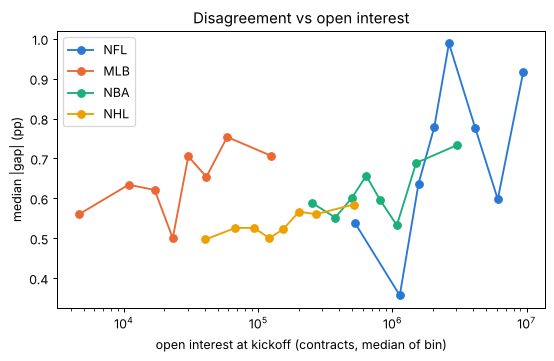

In [17]:
# Picture: median |gap| (pp) by open-interest decile, per sport
fig, ax = plt.subplots(figsize=(7, 4))
for s in SPORT_ORDER:
    d = df[df.sport == s]
    b = pd.qcut(d["log_open_interest"], 8, duplicates="drop")
    g = d.groupby(b, observed=True).agg(oi=("total_open_interest", "median"), gap=("gap_pp", lambda x: x.abs().median()))
    ax.plot(g["oi"], g["gap"], marker="o", label=s.upper(), color=SPORT_COLORS[s])
ax.set_xscale("log"); ax.set_xlabel("open interest at kickoff (contracts, median of bin)")
ax.set_ylabel("median |gap| (pp)"); ax.set_title("Disagreement vs open interest"); ax.legend();

**Reading section 5.**
- **The original hypothesis (more liquidity → smaller disagreement) is not supported for volume or open interest.** Pre-kickoff volume has no detectable effect (×1.007 per log unit, p = 0.32). Open interest goes the *other* way: each 2.7× increase in OI is associated with about 5.5% **larger** |gap| (CI +2% to +9%, p = 0.001).
- The OI result survives every check: controls with and without platform age, within each sport (MLB, NBA, NHL individually significant, NFL same direction), the median and the 90th percentile in quantile regression, and dropping low-volume games.
- **The bid-ask spread behaves as expected:** each extra cent of spread is associated with about 9% larger disagreement (p = 0.023). A wider spread means a noisier Kalshi midpoint. Note that the spread is exactly 1¢ for over 75% of games, so this effect rests on a minority of wide-spread games.
- **Interpreting the OI sign:** OI is the stock of open positions, so it's highest for marquee, heavily traded games. Those are also the games where news and money arrive closest to kickoff, so a Kalshi price taken *at* kickoff can drift from an earlier sportsbook snapshot. That fits the section 3 result (Kalshi more informed than the book). It's a hypothesis, not something these data can confirm. Getting bet365's timestamp would test it.
- `lopsided` has a big effect (×3.7 per unit). Much of that is mechanical, because the de-vig methods disagree most at extreme prices (section 1), so it's a control, not a finding.
- Platform age, season progress, postseason and number of competing leagues have no detectable effect once sport and liquidity are controlled.

## 6. Robustness

### 6a. De-vig method

Kalshi-only calibration (section 2) doesn't depend on the de-vig method at all. The book-side results do.

In [18]:
rows = []
for m in ["proportional", "additive", "power", "cheung"]:   # shin == additive for 2-way markets
    d = with_book_method(df, m)
    _, cb = calibration_fit(d, "logit_book")
    e = encompassing(d)
    r = gamma_fit(f"abs_logit_gap ~ log_open_interest + log_volume + {CONTROLS}", d)
    rows.append({"method": m, "book_beta": cb["beta"], "book_wald_p": cb["wald_p"],
                 "brier_book": ((d.p_book - d.home_win) ** 2).mean(),
                 "book_adds_to_kalshi": e["book_adds_to_kalshi"], "bk_p": e["bk_p"],
                 "kalshi_adds_to_book": e["kalshi_adds_to_book(-b1)"], "kb_p": e["kb_p"],
                 "OI_effect_x": np.exp(r.params["log_open_interest"]), "OI_p": r.pvalues["log_open_interest"],
                 "vol_effect_x": np.exp(r.params["log_volume"]), "vol_p": r.pvalues["log_volume"]})
sensitivity = pd.DataFrame(rows).set_index("method")
sensitivity.round(4)

,book_beta,book_wald_p,brier_book,book_adds_to_kalshi,bk_p,kalshi_adds_to_book,kb_p,OI_effect_x,OI_p,vol_effect_x,vol_p
method,,,,,,,,,,,
proportional,0.9763,0.7592,0.2302,-1.2102,0.0900,-2.1004,0.0022,1.0242,0.1476,1.0025,0.7247
additive,0.9250,0.2382,0.2303,-0.7239,0.2949,-1.6749,0.0172,1.0535,0.0015,1.0064,0.3441
power,0.8969,0.0704,0.2304,-0.2495,0.6998,-1.2035,0.0775,1.0552,0.0004,1.0072,0.2842
cheung,0.9210,0.2068,0.2303,-0.5927,0.3882,-1.5451,0.0278,1.0553,0.0009,1.0068,0.3180


### 6b. Sample restrictions: drop low-volume games; regular season only

In [19]:
samples = {"all games": df,
           "volume >= 100": df[~df.low_volume],
           "regular season": df[df.phase == "regular"]}
rows = []
for name, d in samples.items():
    _, ck = calibration_fit(d, "logit_kalshi")
    e = encompassing(d)
    ctrl = CONTROLS.replace("post + ", "") if name == "regular season" else CONTROLS
    r = gamma_fit(f"abs_logit_gap ~ log_open_interest + log_volume + {ctrl}", d)
    rows.append({"sample": name, "n": len(d), "kalshi_beta": ck["beta"], "kalshi_wald_p": ck["wald_p"],
                 "book_adds_to_kalshi": e["book_adds_to_kalshi"], "bk_p": e["bk_p"],
                 "OI_effect_x": np.exp(r.params["log_open_interest"]), "OI_p": r.pvalues["log_open_interest"],
                 "vol_effect_x": np.exp(r.params["log_volume"]), "vol_p": r.pvalues["log_volume"]})
pd.DataFrame(rows).set_index("sample").round(4)

,n,kalshi_beta,kalshi_wald_p,book_adds_to_kalshi,bk_p,OI_effect_x,OI_p,vol_effect_x,vol_p
sample,,,,,,,,,
all games,4865,0.9427,0.4464,-0.5927,0.3882,1.0553,0.0009,1.0068,0.3180
volume >= 100,3663,0.9737,0.8698,-0.4765,0.5685,1.0479,0.0188,1.0185,0.1317
regular season,4657,0.9482,0.5735,-0.6543,0.3540,1.0653,0.0002,1.0079,0.2474


**Reading section 6.**
- **De-vig method:** the qualitative conclusions hold for every method. Book calibration is not rejected for any method (power is closest, p = 0.07). The book never adds to Kalshi. Kalshi adds to the book under every method (p from 0.002 to 0.08). The positive OI effect is significant for additive, power and Cheung, but not for proportional (×1.024, p = 0.15). That fits section 1: proportional's systematic tilt adds noise to the gap that isn't related to liquidity.
- **Low-volume games:** dropping the 1,202 games with fewer than 100 contracts traded moves Kalshi's slope closer to 1 (0.97, Wald p = 0.87). This is consistent with stale quotes in thin markets adding noise. The OI effect remains (×1.048, p = 0.019).
- **Regular season only:** nothing changes. With only 207 postseason games, the playoffs don't drive any result.

## 7. Strategy and economic significance

**Rules**
- **Signal:** for each game, edge on a side = de-vigged book probability − Kalshi **ask** for that side. Take the larger edge; bet if it exceeds the threshold.
- **Costs:** pay the ask, plus Kalshi's taker fee, $0.07 \cdot P(1-P)$ per contract (rounded up to the cent at the order level; per-contract here, which slightly understates fees on small orders).
- **Stake rules:**
  - flat: 1 unit per bet
  - edge-proportional: units = edge / 0.01
  - ¼-Kelly: fraction of a fixed 100-unit bankroll, $f = \tfrac14 \cdot \frac{p - c}{1 - c}$ with $c$ = ask + fee
- **Validation:** walk-forward. On each training window, pick the (threshold, stake) combination with the best ROI (at least 30 bets), then evaluate it on the next block. Folds are balanced by game count.
- **Uncertainty:** bootstrap ROI by resampling **dates**.

The first fold trains only on MLB, since Kalshi had only MLB before September 2025.

In [20]:
FEE_RATE = 0.07  # Kalshi taker fee multiplier (fee = 0.07 * P * (1 - P) per contract)

def kalshi_fee(price):
    return FEE_RATE * price * (1 - price)


def walk_forward_splits(data, n_folds=5, min_train_frac=0.4):
    # Expanding-window folds; boundaries placed by cumulative game count and snapped to whole dates.
    games_per_date = data.groupby("game_date_et").size().sort_index()
    cum = games_per_date.cumsum() / len(data)
    targets = np.linspace(min_train_frac, 1, n_folds + 1)
    cut_dates = [cum.index[np.searchsorted(cum.values, t, side="left")] for t in targets[:-1]] + [None]
    for a, b in zip(cut_dates[:-1], cut_dates[1:]):
        train = data.index[data["game_date_et"] < a]
        test = data.index[(data["game_date_et"] >= a) & ((data["game_date_et"] < b) if b else True)]
        yield train, test


def candidate_bets(d):
    # One row per game: the better side by book-vs-ask edge, with cost per contract and payoff.
    home_edge = d["p_book"] - d["kalshi_home_ask"]
    away_edge = (1 - d["p_book"]) - d["kalshi_away_ask"]
    home = home_edge >= away_edge
    out = pd.DataFrame(index=d.index)
    out["game_date_et"] = d["game_date_et"]
    out["side"] = np.where(home, "home", "away")
    out["p"] = np.where(home, d["p_book"], 1 - d["p_book"])
    out["ask"] = np.where(home, d["kalshi_home_ask"], d["kalshi_away_ask"])
    out["edge"] = np.where(home, home_edge, away_edge)
    out["cost"] = out["ask"] + kalshi_fee(out["ask"])             # per contract, pays $1 if it wins
    out["won"] = np.where(home, d["home_win"], 1 - d["home_win"])
    out = out[(out["ask"] > 0) & (out["ask"] < 1)]
    return out


def stake_units(b, rule):
    if rule == "flat":
        return pd.Series(1.0, index=b.index)
    if rule == "edge_prop":
        return b["edge"] / 0.01
    if rule == "kelly_q":
        f = 0.25 * (b["p"] - b["cost"]) / (1 - b["cost"])
        return 100 * f.clip(lower=0)
    raise ValueError(rule)


def backtest(bets, threshold, rule):
    b = bets[bets["edge"] > threshold].copy()
    b["stake"] = stake_units(b, rule)            # dollars staked
    b = b[b["stake"] > 0]
    b["contracts"] = b["stake"] / b["cost"]
    b["pnl"] = b["contracts"] * b["won"] - b["stake"]
    return b


def summarize(b):
    staked = b["stake"].sum()
    return {"bets": len(b), "staked": staked, "pnl": b["pnl"].sum(),
            "roi": b["pnl"].sum() / staked if staked > 0 else np.nan,
            "hit_rate": b["won"].mean() if len(b) else np.nan}


def bootstrap_roi(b, n_boot=2000, seed=0):
    # 95% CI for ROI, resampling whole dates.
    if len(b) == 0:
        return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    g = b.groupby("game_date_et").agg(pnl=("pnl", "sum"), stake=("stake", "sum"))
    idx = rng.integers(0, len(g), size=(n_boot, len(g)))
    roi = g["pnl"].values[idx].sum(1) / g["stake"].values[idx].sum(1)
    return tuple(np.percentile(roi, [2.5, 97.5]))


THRESHOLDS = [0.0, 0.01, 0.02, 0.03, 0.05]
RULES = ["flat", "edge_prop", "kelly_q"]
bets_all = candidate_bets(df)
print(f"games with a valid ask: {len(bets_all)};  share with positive edge after ask (before fees): {(bets_all.edge > 0).mean():.3f}")
print(f"mean edge vs ask: {bets_all.edge.mean()*100:.2f} pp;  mean fee per contract: {kalshi_fee(bets_all.ask).mean()*100:.2f} c")

games with a valid ask: 4865;  share with positive edge after ask (before fees): 0.466
mean edge vs ask: 0.05 pp;  mean fee per contract: 1.59 c


### 7a. Baseline: what does buying at the ask cost?

In [21]:
# Cost of trading: ROI from buying every game's home side, favorite, or underdog at the ask.
fav_home = df["p_kalshi"] >= 0.5
sides = {
    "home":     (df["kalshi_home_ask"], df["home_win"]),
    "favorite": (np.where(fav_home, df["kalshi_home_ask"], df["kalshi_away_ask"]), np.where(fav_home, df["home_win"], 1 - df["home_win"])),
    "underdog": (np.where(fav_home, df["kalshi_away_ask"], df["kalshi_home_ask"]), np.where(fav_home, 1 - df["home_win"], df["home_win"])),
}
base = {}
for name, (ask, won) in sides.items():
    ask, won = pd.Series(ask, index=df.index), pd.Series(won, index=df.index)
    ok = (ask > 0) & (ask < 1)
    ask, won = ask[ok], won[ok]
    cost = ask + kalshi_fee(ask)
    base[name] = {"bets": len(ask), "mean_price": ask.mean(), "win_rate": won.mean(),
                  "roi_at_ask": won.sum() / ask.sum() - 1, "roi_after_fees": won.sum() / cost.sum() - 1}
pd.DataFrame(base).T.round(4)

,bets,mean_price,win_rate,roi_at_ask,roi_after_fees
home,4865.0,0.5453,0.5342,-0.0202,-0.0479
favorite,4865.0,0.6221,0.5949,-0.0438,-0.0675
underdog,4865.0,0.3911,0.4051,0.0358,-0.0049


### 7b. In-sample grid (for intuition only; it's optimistic by construction)

In [22]:
grid = []
for t in THRESHOLDS:
    for r in RULES:
        grid.append({"threshold": t, "rule": r, **summarize(backtest(bets_all, t, r))})
grid = pd.DataFrame(grid)
grid.pivot(index="threshold", columns="rule", values="roi").round(4)

rule,edge_prop,flat,kelly_q
threshold,,,
0.00,-0.0606,-0.0738,-0.0375
0.01,-0.0540,-0.0493,-0.0452
0.02,-0.1210,-0.1154,-0.0852
0.03,-0.1982,-0.1543,-0.2561
0.05,-1.0000,-1.0000,-1.0000


In [23]:
grid.pivot(index="threshold", columns="rule", values="bets")

rule,edge_prop,flat,kelly_q
threshold,,,
0.00,2269,2269,124
0.01,386,386,100
0.02,46,46,46
0.03,8,8,8
0.05,1,1,1


### 7c. Walk-forward (out-of-sample)

In [24]:
fold_rows, oos = [], []
for i, (tr, te) in enumerate(walk_forward_splits(df)):
    train_bets, test_bets = bets_all.loc[bets_all.index.intersection(tr)], bets_all.loc[bets_all.index.intersection(te)]
    best, best_roi = None, -np.inf
    for t in THRESHOLDS:
        for r in RULES:
            s = summarize(backtest(train_bets, t, r))
            if s["bets"] >= 30 and s["roi"] > best_roi:
                best, best_roi = (t, r), s["roi"]
    if best is None:
        fold_rows.append({"fold": i, "chosen": "none (<30 bets)"}); continue
    b = backtest(test_bets, *best)
    oos.append(b.assign(fold=i))
    fold_rows.append({"fold": i, "test_from": df.loc[te, "game_date_et"].min(), "test_to": df.loc[te, "game_date_et"].max(),
                      "chosen": f"t={best[0]}, {best[1]}", "train_roi": best_roi, **{f"test_{k}": v for k, v in summarize(b).items()}})
wf = pd.DataFrame(fold_rows).set_index("fold")
wf.round(4)

,test_from,test_to,chosen,train_roi,test_bets,test_staked,test_pnl,test_roi,test_hit_rate
fold,,,,,,,,,
0,2025-09-25,2025-11-09,"t=0.01, flat",0.0351,38,38.0000,3.8347,0.1009,0.6579
1,2025-11-10,2025-12-17,"t=0.01, flat",0.0450,31,31.0000,-1.1185,-0.0361,0.5806
2,2025-12-18,2026-01-23,"t=0.01, flat",0.0361,43,43.0000,-5.4904,-0.1277,0.5349
3,2026-01-24,2026-03-16,"t=0.01, flat",0.0145,27,27.0000,-13.4747,-0.4991,0.3704
4,2026-03-17,2026-06-14,"t=0.0, kelly_q",0.0004,23,13.2958,-3.0137,-0.2267,0.4783


In [25]:
oos_bets = pd.concat(oos) if oos else pd.DataFrame(columns=["stake", "pnl", "won", "game_date_et"])
s = summarize(oos_bets)
lo, hi = bootstrap_roi(oos_bets)
print(f"Out-of-sample: {s['bets']} bets, staked {s['staked']:.1f} units, P&L {s['pnl']:+.1f}, "
      f"ROI {s['roi']:+.2%}  (95% date-bootstrap CI {lo:+.2%} to {hi:+.2%})")

Out-of-sample: 162 bets, staked 152.3 units, P&L -19.3, ROI -12.65%  (95% date-bootstrap CI -27.71% to +1.60%)


**Reading section 7.**
- **Trading costs swamp any edge.** The average book-vs-ask edge is 0.05 pp, while the Kalshi taker fee averages 1.6¢ per contract on top of a bid-ask spread that is usually 1¢. Buying every home side, favorite or underdog at the ask loses 0.5–6.8% after fees. Even the underdog side, which is slightly underpriced (section 2), goes from +3.6% to −0.5% once fees are paid.
- **In-sample**, no threshold/stake combination has positive ROI on the full sample. Larger thresholds leave very few bets (46 at 2 pp, 8 at 3 pp), and those lose.
- **Out-of-sample (walk-forward):** a 1 pp threshold looked mildly profitable on early training windows, but out of sample the chosen rules lost money in 4 of 5 folds. Overall: 162 bets, ROI −12.7% (95% date-bootstrap CI −27.7% to +1.6%).
- **Conclusion:** no exploitable strategy from following the sportsbook against Kalshi exists in this sample after realistic costs. Statistically and economically, the markets are efficient relative to each other at this resolution.
- **Caveats:** this uses closing quotes, not order-book depth, so large stakes would face worse prices. Fees are applied per contract without rounding. Both caveats make the real result *worse*, not better.

## Summary: answers to the research questions

**Q3: Are these sports prediction markets significantly inefficient?** No, at the resolution these data allow.
| Form | Test | Result |
|---|---|---|
| Calibration (baseline) | logit(win) on logit(price), joint α=0, β=1 | Not rejected for Kalshi (p = 0.45) or bet365 (p = 0.21). β ∈ [0.84, 1.04] for Kalshi |
| Weak | past prices beyond the close | **Untested**: needs an earlier Kalshi candle |
| Semi-strong | does the public sportsbook price add to Kalshi? | No (p = 0.39). The reverse holds: Kalshi adds to bet365 (p = 0.028) |
| Strong | private information | Not testable with public data |

**Q2: How do liquidity and volume relate to inefficiency?** Pre-kickoff volume: no relationship. Wider bid-ask spreads: larger disagreement, as expected. Open interest: *larger* disagreement, robustly. The likely reason is that heavily traded games move more near kickoff, relative to an earlier book snapshot. This is a hypothesis to state, not a result.

**Q1: Is there a profitable strategy?** No. The edge versus the ask averages 0.05 pp against about 1.6¢ in fees. Walk-forward ROI is −12.7% (CI −27.7% to +1.6%).

**De-vigging (prof. comment #3):** the method flips the sign of the mean gap but doesn't change any conclusion above (section 6a).

**Season / sport / time (prof. comment #4):** sport, postseason, season progress, platform age and competing leagues are all controlled. Slopes don't differ by sport, and postseason and regular-season-only results match. The one caveat: platform age and sport are confounded, because MLB is the only sport from Kalshi's first months.

**Limitations:** single season per sport; a single sportsbook with an unknown snapshot time; closing quotes only (no depth); 9 NFL playoff games; weak form untested.